# UAV Flight Analysis — Phase 3 (restart-safe continuation)

This is a **clean continuation notebook**, not a replacement for the exploratory history in `05-flight-session-analysis.ipynb`. It loads verified on-disk datasets instead of rerunning the original 102 `.bin` recordings or older debugging tests. Run cells from top to bottom after restarting the kernel.

**Prerequisites:** `outputs/diagnostics/uav_dataset_master_index.csv`, `outputs/analysis/consolidated_flight_sessions.csv`, `outputs/analysis/session_report_manifest.csv`, and `src/session_statistics.py`.

`STRONG_CANDIDATE` is *not* a confirmed flight.

In [1]:
# 1 — Restore project paths and imports after a kernel restart
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        f"Cannot find src/ at {PROJECT_ROOT}. Open this notebook from D:/Drone-research/notebooks "
        "or D:/Drone-research."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("PASS: Project environment restored!")

Project root: D:\Drone-research
PASS: Project environment restored!


In [2]:
# 2 — Restore already-verified results from disk (no .bin reprocessing)
master_index_path = PROJECT_ROOT / "outputs" / "diagnostics" / "uav_dataset_master_index.csv"
sessions_path = PROJECT_ROOT / "outputs" / "analysis" / "consolidated_flight_sessions.csv"
manifest_path = PROJECT_ROOT / "outputs" / "analysis" / "session_report_manifest.csv"

for path in (master_index_path, sessions_path, manifest_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing previously exported dataset: {path}")

master_index = pd.read_csv(master_index_path)
saved_sessions = pd.read_csv(sessions_path)
saved_manifest = pd.read_csv(manifest_path)
sessions = saved_sessions.copy()

assert len(master_index) == 102 and master_index["LogFile"].is_unique
assert master_index["Status"].value_counts().to_dict() == {
    "SUCCESS": 50, "FAILED": 27, "NO_COMPLETE_SESSIONS": 25
}
assert len(saved_sessions) == 158 and len(saved_manifest) == 50
assert saved_sessions["LogFile"].nunique() == 50
assert not saved_sessions.duplicated(["LogFile", "Session"]).any()
assert set(saved_sessions["LogFile"]) == set(saved_manifest["LogFile"])

print("Logs indexed:", len(master_index))
print("Consolidated armed sessions:", len(saved_sessions))
print("Report manifest records:", len(saved_manifest))
print("PASS: Verified datasets restored from disk!")

Logs indexed: 102
Consolidated armed sessions: 158
Report manifest records: 50
PASS: Verified datasets restored from disk!


In [3]:
# 3 — Regenerate statistical analyses using the current reusable module
import importlib
import src.session_statistics as session_statistics
importlib.reload(session_statistics)

stat_results = session_statistics.analyze_session_statistics(saved_sessions)
assert isinstance(stat_results, dict) and "Summary" in stat_results
summary = stat_results["Summary"].iloc[0]
assert int(summary["UniqueRecordings"]) == 50
assert int(summary["ArmedSessions"]) == 158
assert abs(float(summary["TotalDetectedActivitySec"]) - 2270.003) < 0.1
assert abs(float(summary["Top1ActivitySharePct"]) - 33.01) < 0.1
assert abs(float(summary["Top5ActivitySharePct"]) - 63.24) < 0.1
assert abs(float(summary["Top10ActivitySharePct"]) - 83.62) < 0.1
assert int(summary["StrongCandidateSessions"]) == 11
assert int(summary["ReviewRequiredSessions"]) == 61
assert int(summary["LowActivitySessions"]) == 86

print("STATISTICAL ANALYSIS SUMMARY")
display(stat_results["Summary"].round(3))
print("PASS: Saved sessions reproduce prior statistical results!")

STATISTICAL ANALYSIS SUMMARY


,UniqueRecordings,ArmedSessions,TotalDetectedActivitySec,Top1ActivitySharePct,Top5ActivitySharePct,Top10ActivitySharePct,StrongCandidateSessions,ReviewRequiredSessions,LowActivitySessions
0,50,158,2270.003,33.009,63.242,83.617,11,61,86


PASS: Saved sessions reproduce prior statistical results!


## Current checkpoint — Export statistical reports

This is the next pending task from Phase 3. It writes new statistical CSVs under `outputs/analysis/statistics/`, leaving the verified master index and consolidated session CSV unchanged.

In [5]:
# 4 — Export every statistical output, then verify persistence
statistics_dir = PROJECT_ROOT / "outputs" / "analysis" / "statistics"
statistics_dir.mkdir(parents=True, exist_ok=True)

print("STATISTICAL REPORT EXPORT")
for name, frame in stat_results.items():
    if not isinstance(frame, pd.DataFrame):
        raise TypeError(f"Output {name!r} is not a DataFrame")
    output_path = statistics_dir / f"{name.lower()}.csv"
    frame.to_csv(output_path, index=False)
    restored = pd.read_csv(output_path)
    assert restored.shape == frame.shape, f"Export shape mismatch: {name}"
    print(f"{name}: {frame.shape[0]} rows x {frame.shape[1]} columns -> {output_path.name}")

print("Location:", statistics_dir)
print("PASS: Statistical reports exported and verified!")

STATISTICAL REPORT EXPORT
Baseline: 4 rows x 9 columns -> baseline.csv
Classification: 3 rows x 10 columns -> classification.csv
Recordings: 50 rows x 11 columns -> recordings.csv
Concentration: 50 rows x 13 columns -> concentration.csv
Summary: 1 rows x 9 columns -> summary.csv
Location: D:\Drone-research\outputs\analysis\statistics
PASS: Statistical reports exported and verified!


## Next planned step

After the export is verified, investigate the distributions of armed-session duration, motor activity ratio and telemetry coverage, then examine potential outliers. Keep research validation separate from classifier-generated labels.

ARMED-SESSION DURATION DISTRIBUTION
--------------------------------------------------
Sessions: 158
Mean duration: 33.31 seconds
Median duration: 23.55 seconds
Minimum duration: 3.2 seconds
Maximum duration: 271.8 seconds


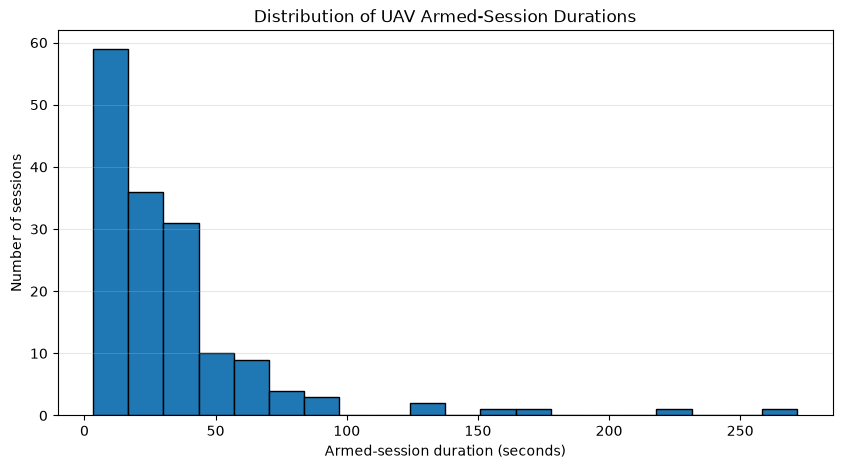


PASS: Session-duration distribution generated!


In [6]:
# PHASE 3 — ARMED-SESSION DURATION DISTRIBUTION

import pandas as pd
import matplotlib.pyplot as plt

sessions = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "consolidated_flight_sessions.csv"
)

durations = pd.to_numeric(
    sessions["ArmedDurationSec"],
    errors="coerce"
).dropna()

assert len(durations) == 158
assert durations.ge(0).all()

print("ARMED-SESSION DURATION DISTRIBUTION")
print("-" * 50)

print("Sessions:", len(durations))
print("Mean duration:", round(durations.mean(), 2), "seconds")
print("Median duration:", round(durations.median(), 2), "seconds")
print("Minimum duration:", round(durations.min(), 2), "seconds")
print("Maximum duration:", round(durations.max(), 2), "seconds")

plt.figure(figsize=(10, 5))
plt.hist(durations, bins=20, edgecolor="black")
plt.xlabel("Armed-session duration (seconds)")
plt.ylabel("Number of sessions")
plt.title("Distribution of UAV Armed-Session Durations")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nPASS: Session-duration distribution generated!")

In [7]:
# PHASE 3 — DURATION OUTLIER SCREENING (IQR)

import pandas as pd

q1 = durations.quantile(0.25)
q3 = durations.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

potential_outliers = sessions.loc[
    (sessions["ArmedDurationSec"] < lower_bound)
    | (sessions["ArmedDurationSec"] > upper_bound)
].copy()

potential_outliers = potential_outliers.sort_values(
    "ArmedDurationSec",
    ascending=False
)

print("DURATION OUTLIER SCREENING")
print("-" * 55)

print(f"Q1: {q1:.3f} seconds")
print(f"Q3: {q3:.3f} seconds")
print(f"IQR: {iqr:.3f} seconds")
print(f"Lower bound: {lower_bound:.3f} seconds")
print(f"Upper bound: {upper_bound:.3f} seconds")

print("\nPotential outlier sessions:", len(potential_outliers))

display(
    potential_outliers[
        [
            "LogFile",
            "Session",
            "ArmedDurationSec",
            "ActivityRatio",
            "CoverageRatio",
            "SessionClassification"
        ]
    ].round(3)
)

assert len(potential_outliers) <= len(sessions)

print("\nPASS: Duration outlier screening completed!")

DURATION OUTLIER SCREENING
-------------------------------------------------------
Q1: 9.902 seconds
Q3: 39.975 seconds
IQR: 30.073 seconds
Lower bound: -35.207 seconds
Upper bound: 85.084 seconds

Potential outlier sessions: 8


,LogFile,Session,ArmedDurationSec,ActivityRatio,CoverageRatio,SessionClassification
29,2026-07-02 18-37-42.bin,6,271.80,0.873,1.000,STRONG_CANDIDATE
16,1980-01-11 18-54-46.bin,4,220.20,0.838,1.000,REVIEW_REQUIRED
33,2026-07-08 18-21-10.bin,1,169.95,0.927,1.000,STRONG_CANDIDATE
27,2026-07-02 18-37-42.bin,4,158.20,0.857,0.999,STRONG_CANDIDATE
25,2026-07-02 18-37-42.bin,2,135.50,0.734,0.999,STRONG_CANDIDATE
31,2026-07-02 18-37-42.bin,8,128.50,0.806,0.999,STRONG_CANDIDATE
26,2026-07-02 18-37-42.bin,3,89.73,0.732,1.000,STRONG_CANDIDATE
36,2026-07-13 18-57-45.bin,1,86.10,0.727,0.999,REVIEW_REQUIRED



PASS: Duration outlier screening completed!


DURATION VS MOTOR ACTIVITY
-------------------------------------------------------
Sessions analyzed: 158
Spearman correlation: 0.655

CLASSIFICATION COUNTS
SessionClassification
LOW_ACTIVITY        86
REVIEW_REQUIRED     61
STRONG_CANDIDATE    11
Name: count, dtype: int64


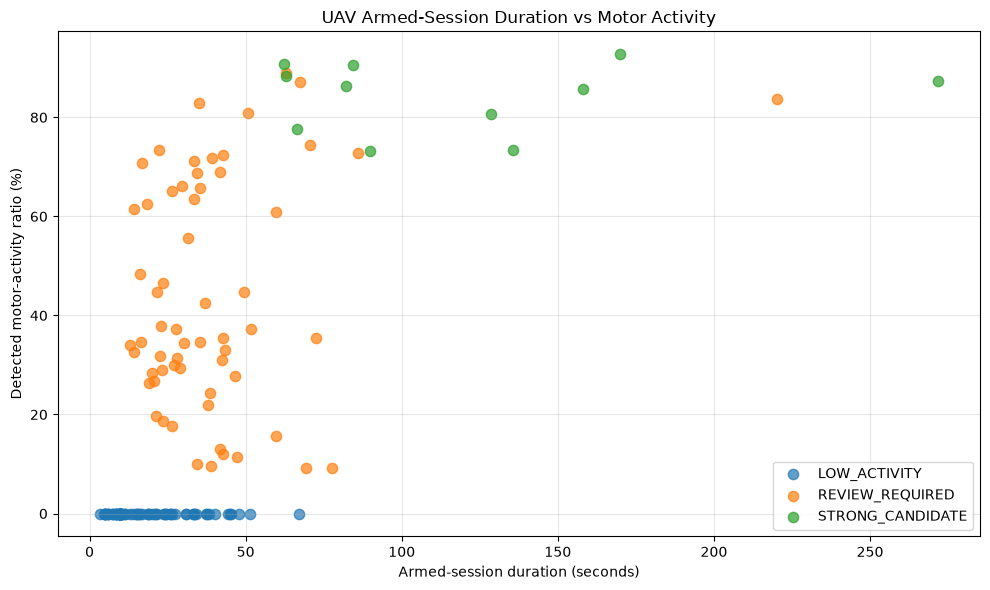


PASS: Duration-activity relationship analyzed!


In [8]:
# PHASE 3 — DURATION VS MOTOR ACTIVITY

import pandas as pd
import matplotlib.pyplot as plt

sessions = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "consolidated_flight_sessions.csv"
)

required = [
    "LogFile",
    "Session",
    "ArmedDurationSec",
    "ActivityRatio",
    "SessionClassification"
]

assert set(required).issubset(sessions.columns)
assert len(sessions) == 158

plot_data = sessions[required].copy()

plot_data["ArmedDurationSec"] = pd.to_numeric(
    plot_data["ArmedDurationSec"],
    errors="coerce"
)

plot_data["ActivityRatio"] = pd.to_numeric(
    plot_data["ActivityRatio"],
    errors="coerce"
)

plot_data = plot_data.dropna(
    subset=["ArmedDurationSec", "ActivityRatio"]
)

assert len(plot_data) == 158
assert plot_data["ActivityRatio"].between(0, 1).all()

print("DURATION VS MOTOR ACTIVITY")
print("-" * 55)

correlation = plot_data[
    ["ArmedDurationSec", "ActivityRatio"]
].corr(method="spearman").iloc[0, 1]

print("Sessions analyzed:", len(plot_data))
print("Spearman correlation:", round(correlation, 3))

print("\nCLASSIFICATION COUNTS")
print(plot_data["SessionClassification"].value_counts())

plt.figure(figsize=(10, 6))

for classification, group in plot_data.groupby(
    "SessionClassification"
):
    plt.scatter(
        group["ArmedDurationSec"],
        group["ActivityRatio"] * 100,
        label=classification,
        alpha=0.7,
        s=55
    )

plt.xlabel("Armed-session duration (seconds)")
plt.ylabel("Detected motor-activity ratio (%)")
plt.title("UAV Armed-Session Duration vs Motor Activity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nPASS: Duration-activity relationship analyzed!")

In [9]:
# PHASE 3 — CORRELATION ROBUSTNESS CHECK

import pandas as pd

dominant_log = "2026-07-02 18-37-42.bin"

def calculate_spearman(frame):
    return frame[
        ["ArmedDurationSec", "ActivityRatio"]
    ].corr(method="spearman").iloc[0, 1]

all_sessions = sessions.copy()

without_dominant = sessions.loc[
    sessions["LogFile"] != dominant_log
].copy()

active_sessions = sessions.loc[
    sessions["ActivityRatio"] > 0
].copy()

active_without_dominant = sessions.loc[
    (sessions["ActivityRatio"] > 0)
    & (sessions["LogFile"] != dominant_log)
].copy()

comparisons = pd.DataFrame([
    {
        "Dataset": "All sessions",
        "Sessions": len(all_sessions),
        "SpearmanCorrelation": calculate_spearman(all_sessions)
    },
    {
        "Dataset": "Excluding dominant recording",
        "Sessions": len(without_dominant),
        "SpearmanCorrelation": calculate_spearman(without_dominant)
    },
    {
        "Dataset": "Positive motor activity only",
        "Sessions": len(active_sessions),
        "SpearmanCorrelation": calculate_spearman(active_sessions)
    },
    {
        "Dataset": "Positive activity, excluding dominant",
        "Sessions": len(active_without_dominant),
        "SpearmanCorrelation": calculate_spearman(active_without_dominant)
    }
])

print("CORRELATION ROBUSTNESS ANALYSIS")
print("-" * 60)

display(comparisons.round(3))

assert len(all_sessions) == 158
assert len(without_dominant) < 158
assert len(active_sessions) > 0
assert comparisons["SpearmanCorrelation"].notna().all()

print("\nPASS: Correlation robustness analysis completed!")

CORRELATION ROBUSTNESS ANALYSIS
------------------------------------------------------------


,Dataset,Sessions,SpearmanCorrelation
0,All sessions,158,0.655
1,Excluding dominant recording,149,0.603
2,Positive motor activity only,72,0.411
3,"Positive activity, excluding dominant",65,0.245



PASS: Correlation robustness analysis completed!


MOTOR ACTIVITY RATIO DISTRIBUTION
-------------------------------------------------------
Total sessions: 158
Zero-activity sessions: 86
Positive-activity sessions: 72
Median activity ratio: 0.0
Mean activity ratio: 0.227

POSITIVE-ACTIVITY SESSIONS
count    72.000
mean      0.499
std       0.261
min       0.092
25%       0.292
50%       0.447
75%       0.728
max       0.927
Name: ActivityRatio, dtype: float64


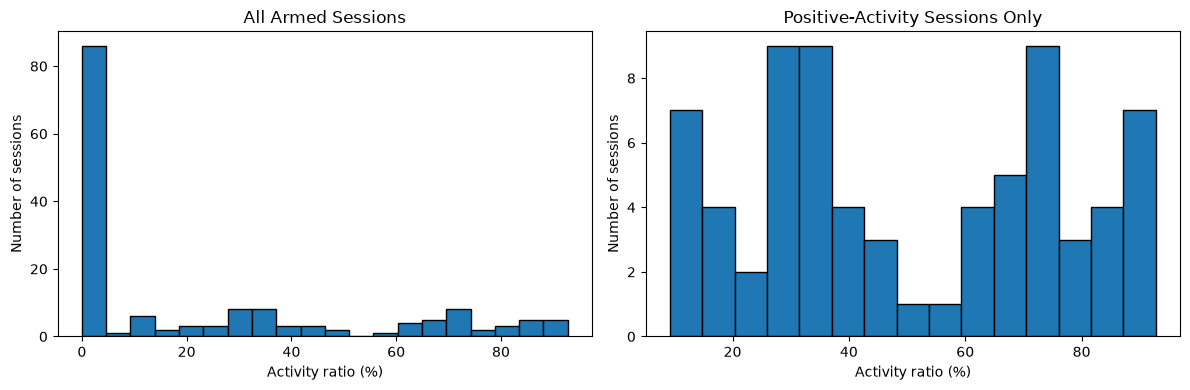


PASS: Motor-activity distribution verified!


In [10]:
# PHASE 3 — MOTOR ACTIVITY RATIO DISTRIBUTION

import pandas as pd
import matplotlib.pyplot as plt

sessions = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "consolidated_flight_sessions.csv"
)

activity = pd.to_numeric(
    sessions["ActivityRatio"],
    errors="coerce"
)

assert len(activity) == 158
assert activity.notna().all()
assert activity.between(0, 1).all()

zero_activity = (activity == 0).sum()
positive_activity = (activity > 0).sum()

print("MOTOR ACTIVITY RATIO DISTRIBUTION")
print("-" * 55)

print("Total sessions:", len(activity))
print("Zero-activity sessions:", zero_activity)
print("Positive-activity sessions:", positive_activity)
print("Median activity ratio:", round(activity.median(), 3))
print("Mean activity ratio:", round(activity.mean(), 3))

print("\nPOSITIVE-ACTIVITY SESSIONS")
print(activity[activity > 0].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    activity * 100,
    bins=20,
    edgecolor="black"
)
axes[0].set_title("All Armed Sessions")
axes[0].set_xlabel("Activity ratio (%)")
axes[0].set_ylabel("Number of sessions")

axes[1].hist(
    activity[activity > 0] * 100,
    bins=15,
    edgecolor="black"
)
axes[1].set_title("Positive-Activity Sessions Only")
axes[1].set_xlabel("Activity ratio (%)")
axes[1].set_ylabel("Number of sessions")

plt.tight_layout()
plt.show()

assert zero_activity == 86
assert positive_activity == 72

print("\nPASS: Motor-activity distribution verified!")

TELEMETRY COVERAGE COMPARISON
-------------------------------------------------------


,ActivityGroup,Sessions,MeanCoverage,MedianCoverage,MinimumCoverage,MaximumCoverage
0,Positive activity,72,0.9972,0.9974,0.9923,0.9998
1,Zero activity,86,0.9913,0.9904,0.9686,0.9992



SESSIONS WITH COVERAGE BELOW 98%


,LogFile,Session,ActivityRatio,CoverageRatio,CoverageSufficient,ActivityGroup
19,1980-01-11 18-54-46.bin,7,0.0,0.9686,True,Zero activity
73,79 01-01-1980 05-30-00 AM.bin,1,0.0,0.9786,True,Zero activity
45,27 01-01-1980 05-30-00 AM.bin,4,0.0,0.9790,True,Zero activity
8,1980-01-10 19-03-03.bin,2,0.0,0.9791,True,Zero activity
65,2026-07-02 19-00-27.bin,1,0.0,0.9791,True,Zero activity
18,1980-01-11 18-54-46.bin,6,0.0,0.9791,True,Zero activity


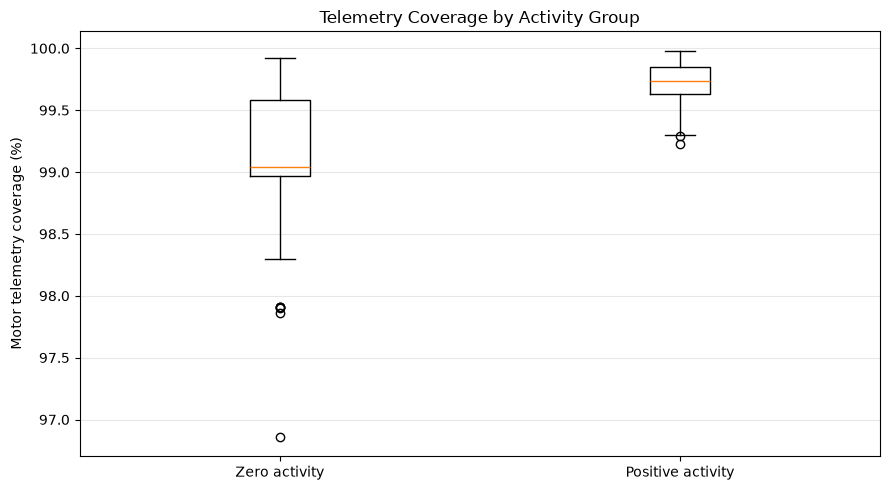


PASS: Telemetry coverage comparison completed!


In [11]:
# PHASE 3 — TELEMETRY COVERAGE COMPARISON

import pandas as pd
import matplotlib.pyplot as plt

sessions = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "consolidated_flight_sessions.csv"
)

coverage_data = sessions[
    [
        "LogFile",
        "Session",
        "ActivityRatio",
        "CoverageRatio",
        "CoverageSufficient"
    ]
].copy()

coverage_data["ActivityGroup"] = (
    coverage_data["ActivityRatio"]
    .gt(0)
    .map({
        False: "Zero activity",
        True: "Positive activity"
    })
)

coverage_summary = (
    coverage_data
    .groupby("ActivityGroup")
    .agg(
        Sessions=("Session", "size"),
        MeanCoverage=("CoverageRatio", "mean"),
        MedianCoverage=("CoverageRatio", "median"),
        MinimumCoverage=("CoverageRatio", "min"),
        MaximumCoverage=("CoverageRatio", "max")
    )
    .reset_index()
)

print("TELEMETRY COVERAGE COMPARISON")
print("-" * 55)

display(coverage_summary.round(4))

print("\nSESSIONS WITH COVERAGE BELOW 98%")

low_coverage = coverage_data.loc[
    coverage_data["CoverageRatio"] < 0.98
].sort_values("CoverageRatio")

display(low_coverage.round(4))

plt.figure(figsize=(9, 5))

groups = [
    coverage_data.loc[
        coverage_data["ActivityGroup"] == group,
        "CoverageRatio"
    ] * 100
    for group in ["Zero activity", "Positive activity"]
]

plt.boxplot(
    groups,
    tick_labels=["Zero activity", "Positive activity"]
)

plt.ylabel("Motor telemetry coverage (%)")
plt.title("Telemetry Coverage by Activity Group")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

assert len(coverage_data) == 158
assert coverage_data["CoverageRatio"].notna().all()

print("\nPASS: Telemetry coverage comparison completed!")

In [12]:
# PHASE 3 — EXPORT DURATION OUTLIER REPORT

import pandas as pd

outlier_dir = PROJECT_ROOT / "outputs" / "analysis" / "outliers"
outlier_dir.mkdir(parents=True, exist_ok=True)

outlier_path = outlier_dir / "duration_outliers_iqr.csv"

# Recalculate the thresholds from saved session data
q1 = sessions["ArmedDurationSec"].quantile(0.25)
q3 = sessions["ArmedDurationSec"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = sessions.loc[
    (sessions["ArmedDurationSec"] < lower)
    | (sessions["ArmedDurationSec"] > upper)
].copy()

outliers["OutlierMethod"] = "IQR_1.5"
outliers["LowerThresholdSec"] = lower
outliers["UpperThresholdSec"] = upper

outliers.to_csv(outlier_path, index=False)

# Verify the saved report
verified = pd.read_csv(outlier_path)

assert len(verified) == 8
assert not verified.duplicated(["LogFile", "Session"]).any()
assert set(zip(verified["LogFile"], verified["Session"])) == set(
    zip(outliers["LogFile"], outliers["Session"])
)

print("DURATION OUTLIER REPORT EXPORTED")
print("-" * 50)
print("Potential outliers:", len(verified))
print("Upper threshold:", round(upper, 3), "seconds")
print("Location:", outlier_path)

print("\nPASS: Duration outlier report saved and verified!")

DURATION OUTLIER REPORT EXPORTED
--------------------------------------------------
Potential outliers: 8
Upper threshold: 85.084 seconds
Location: D:\Drone-research\outputs\analysis\outliers\duration_outliers_iqr.csv

PASS: Duration outlier report saved and verified!


In [13]:
# PHASE 3 — ANOMALY FEATURE READINESS CHECK

import pandas as pd
import numpy as np

sessions = pd.read_csv(
    PROJECT_ROOT
    / "outputs"
    / "analysis"
    / "consolidated_flight_sessions.csv"
)

features = [
    "ArmedDurationSec",
    "TotalActivitySec",
    "ActivityRatio",
    "CoverageRatio"
]

feature_data = sessions[features].apply(
    pd.to_numeric,
    errors="coerce"
)

feature_summary = pd.DataFrame({
    "MissingValues": feature_data.isna().sum(),
    "UniqueValues": feature_data.nunique(),
    "Minimum": feature_data.min(),
    "Maximum": feature_data.max(),
    "StandardDeviation": feature_data.std()
})

print("ANOMALY FEATURE READINESS")
print("-" * 55)

display(feature_summary.round(4))

print("\nDATA INTEGRITY")

print("Total sessions:", len(feature_data))
print("Complete feature rows:", len(feature_data.dropna()))

print(
    "Infinite values:",
    np.isinf(feature_data.to_numpy()).sum()
)

assert len(feature_data) == 158
assert feature_data.notna().all().all()
assert np.isfinite(feature_data.to_numpy()).all()

assert feature_data["ArmedDurationSec"].gt(0).all()
assert feature_data["TotalActivitySec"].ge(0).all()
assert feature_data["ActivityRatio"].between(0, 1).all()
assert feature_data["CoverageRatio"].between(0, 1).all()

print("\nPASS: Anomaly feature readiness verified!")

ANOMALY FEATURE READINESS
-------------------------------------------------------


,MissingValues,UniqueValues,Minimum,Maximum,StandardDeviation
ArmedDurationSec,0,158,3.1995,271.7997,36.5868
TotalActivitySec,0,73,0.0000,237.2999,33.2360
ActivityRatio,0,73,0.0000,0.9273,0.3051
CoverageRatio,0,158,0.9686,0.9998,0.0052



DATA INTEGRITY
Total sessions: 158
Complete feature rows: 158
Infinite values: 0

PASS: Anomaly feature readiness verified!
